# Module 2 · Heterogeneous Treatment Effects with EconML
**⏱ 45 minutes** · 1:00 – 1:45

**Learning objectives**
1. Explain **Double / Debiased Machine Learning (DML)**: orthogonalization + cross-fitting — and implement the core idea in 6 lines.
2. Estimate **CATE** with LinearDML, CausalForestDML, DR-Learner and meta-learners (S/T/X).
3. Select among CATE models **without ground truth** (R-score) and quantify uncertainty (confidence intervals).
4. Turn CATE estimates into an **interpretable, cost-aware targeting policy**.

**Scenario A (continued):** The ATE of a CLI is ~\$370. But *for whom* is it large, and for whom is it negative? A credit line increase also carries cost (expected credit loss, capital) — so we only want to grant it where the incremental spend pays for it.

In [1]:
import sys, pathlib, warnings
sys.path.insert(0, str(pathlib.Path.cwd().parent))
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, cross_val_predict, KFold
from lightgbm import LGBMRegressor, LGBMClassifier
from causal_utils import make_credit_line_data

pd.set_option("display.precision", 2)
df = make_credit_line_data(n=10_000, seed=42)
X_COLS = ["income_k", "credit_score", "utilization", "tenure", "age"]   # effect modifiers (also confounders)

train, test = train_test_split(df, test_size=0.3, random_state=0)
Y, T, X = train["spend"].values, train["cli"].values, train[X_COLS].values
X_test, tau_test = test[X_COLS].values, test["true_cate"].values

# Fast, regularized nuisance learners (re-used throughout)
def reg(): return LGBMRegressor(n_estimators=200, learning_rate=0.05, num_leaves=15, verbose=-1)
def clf(): return LGBMClassifier(n_estimators=200, learning_rate=0.05, num_leaves=15, verbose=-1)
print(f"train={len(train):,}  test={len(test):,}  true ATE={df.true_cate.mean():,.0f}  "
      f"true CATE sd={df.true_cate.std():,.0f}")

train=7,000  test=3,000  true ATE=367  true CATE sd=410


## 2.1 From ATE to CATE — why the average isn't enough

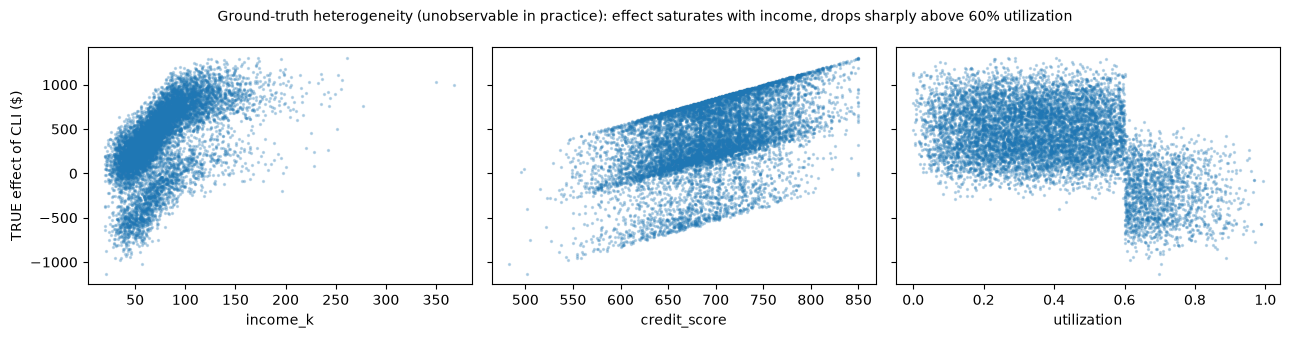

Share of customers with NEGATIVE true effect: 16.5%


In [2]:
fig, ax = plt.subplots(1, 3, figsize=(13, 3.4), sharey=True)
for a, col in zip(ax, ["income_k", "credit_score", "utilization"]):
    a.scatter(df[col], df.true_cate, s=2, alpha=.25)
    a.set_xlabel(col)
ax[0].set_ylabel("TRUE effect of CLI ($)")
fig.suptitle("Ground-truth heterogeneity (unobservable in practice): effect saturates with income, "
             "drops sharply above 60% utilization", fontsize=10)
plt.tight_layout(); plt.show()
print(f"Share of customers with NEGATIVE true effect: {(df.true_cate < 0).mean():.1%}")

## 2.2 Double Machine Learning in one slide

Partially linear model: $\;Y = \theta(X)\,T + g(X) + \varepsilon,\qquad T = m(X) + \eta$

**Idea (Robinson 1988 / Chernozhukov et al. 2018):**
1. Predict $Y$ from $X$ with any ML model → residual $\tilde Y = Y - \hat E[Y\mid X]$
2. Predict $T$ from $X$ with any ML model → residual $\tilde T = T - \hat E[T\mid X]$
3. Regress $\tilde Y$ on $\tilde T$ → causal effect $\theta$

**Why it works:** residualizing removes the part of $T$ explained by confounders (only "as-good-as-random" variation remains). The moment condition is **Neyman-orthogonal**, so small errors in the ML nuisance models have only *second-order* impact on $\theta$. **Cross-fitting** (predict each fold with models trained on other folds) prevents overfitting bias.

Let's demystify it with plain scikit-learn:

In [3]:
kf = KFold(5, shuffle=True, random_state=0)
y_res = Y - cross_val_predict(reg(), X, Y, cv=kf)                              # step 1
t_res = T - cross_val_predict(clf(), X, T, cv=kf, method="predict_proba")[:, 1]  # step 2
theta = (t_res @ y_res) / (t_res @ t_res)                                     # step 3 (OLS, no intercept)
print(f"Hand-rolled DML estimate: ${theta:,.0f}   (true ATE ${df.true_cate.mean():,.0f})")

Hand-rolled DML estimate: $299   (true ATE $367)


Close to the truth, but not equal: with **heterogeneous** effects, a single-coefficient DML returns a *variance-weighted* average that over-weights customers whose propensity is near 0.5. That's one more reason to model the effect as a function $\theta(X)$.

That's DML for a *constant* effect. **EconML** generalizes it: $\theta(X)$ can be linear (LinearDML), a forest (CausalForestDML), or anything else — plus valid confidence intervals, multiple/continuous treatments, instruments and interpretation tools.

## 2.3 The EconML estimator zoo

| Family | Estimators | Strength | Weakness |
|---|---|---|---|
| **DML** | `LinearDML`, `SparseLinearDML`, `CausalForestDML` | Orthogonal, CIs, continuous T | Final-stage form matters |
| **Doubly robust** | `DRLearner`, `ForestDRLearner`, `LinearDRLearner` | Consistent if *either* outcome or propensity model is right | High variance with extreme propensities |
| **Meta-learners** | `SLearner`, `TLearner`, `XLearner`, `DomainAdaptationLearner` | Simple, any ML model | No orthogonality; S-learner shrinks effects toward 0 |
| **IV** | `OrthoIV`, `DMLIV`, `DRIV` | Handles unmeasured confounding (given an instrument) | Needs a valid, strong instrument |

All share the same API: `est.fit(Y, T, X=X, W=W)` → `est.effect(X_new)` → `est.effect_interval(X_new)`.

> `X` = **effect modifiers** (heterogeneity), `W` = **controls only** (confounders that don't modify the effect). Here we put all confounders in `X`.

In [4]:
from econml.dml import LinearDML, CausalForestDML
from econml.dr import ForestDRLearner
from econml.metalearners import SLearner, TLearner, XLearner

models = {
    "LinearDML": LinearDML(model_y=reg(), model_t=clf(), discrete_treatment=True, cv=3, random_state=0),
    "CausalForestDML": CausalForestDML(model_y=reg(), model_t=clf(), discrete_treatment=True, cv=3,
                                       n_estimators=500, min_samples_leaf=20, random_state=0),
    "ForestDRLearner": ForestDRLearner(model_propensity=clf(), model_regression=reg(), cv=3,
                                       n_estimators=500, min_samples_leaf=20, random_state=0),
    "S-Learner": SLearner(overall_model=reg()),
    "T-Learner": TLearner(models=reg()),
    "X-Learner": XLearner(models=reg(), propensity_model=clf()),
}
cate = {}
for name, est in models.items():
    est.fit(Y, T, X=X)
    cate[name] = est.effect(X_test)

# Only possible in simulation: compare to the true CATE
scores = pd.DataFrame({
    "est. ATE ($)": {k: v.mean() for k, v in cate.items()},
    "CATE RMSE ($)": {k: np.sqrt(np.mean((v - tau_test) ** 2)) for k, v in cate.items()},
    "corr(est, true)": {k: np.corrcoef(v, tau_test)[0, 1] for k, v in cate.items()},
}).sort_values("CATE RMSE ($)")
print(f"True ATE on test set: ${tau_test.mean():,.0f}")
scores

True ATE on test set: $366


,est. ATE ($),CATE RMSE ($),"corr(est, true)"
ForestDRLearner,376.16,130.42,0.95
CausalForestDML,315.18,168.71,0.94
S-Learner,333.00,170.62,0.92
X-Learner,361.61,199.25,0.89
LinearDML,349.06,222.44,0.84
T-Learner,390.83,340.24,0.79


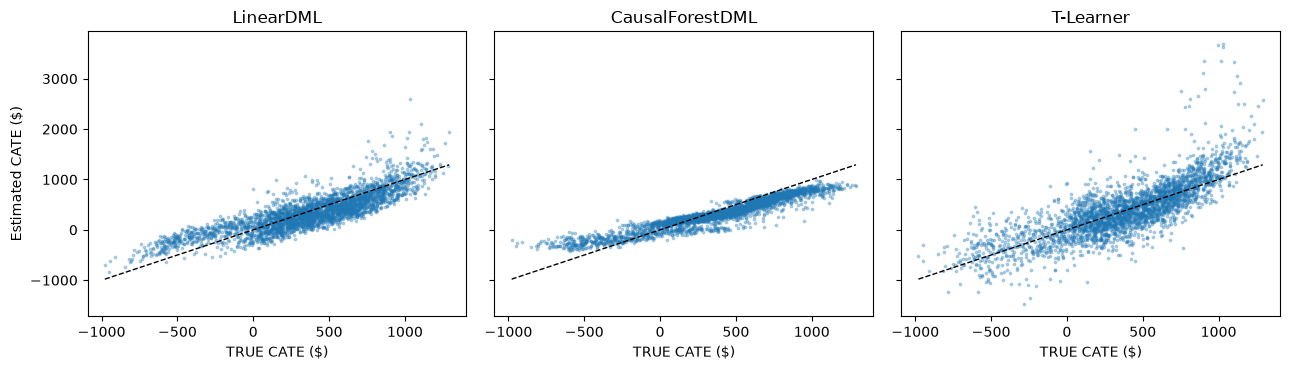

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8), sharex=True, sharey=True)
for ax, name in zip(axes, ["LinearDML", "CausalForestDML", "T-Learner"]):
    ax.scatter(tau_test, cate[name], s=3, alpha=.3)
    lims = [tau_test.min(), tau_test.max()]
    ax.plot(lims, lims, "k--", lw=1); ax.set_title(name)
    ax.set_xlabel("TRUE CATE ($)")
axes[0].set_ylabel("Estimated CATE ($)")
plt.tight_layout(); plt.show()

**What we see**
- **LinearDML** captures the main trends but can't represent the utilization *cliff* or income saturation — misspecified final stage.
- **Forest-based** estimators adapt to non-linear heterogeneity.
- **T-Learner** is noisy: two separate outcome models, each with its own error, and their difference amplifies noise.

## 2.4 Model selection *without* ground truth: the R-score
In production you don't have `true_cate`. EconML's `RScorer` evaluates CATE models on held-out data via the **R-loss** (Nie & Wager): how well $\hat\tau(X)$ explains residualized outcomes from residualized treatment. Higher is better.

In [6]:
from econml.score import RScorer
scorer = RScorer(model_y=reg(), model_t=clf(), discrete_treatment=True, cv=3, random_state=0)
scorer.fit(test["spend"].values, test["cli"].values, X=X_test)
rscores = pd.Series({name: scorer.score(est) for name, est in models.items()}).sort_values(ascending=False)
pd.DataFrame({"R-score (higher=better)": rscores, "true CATE RMSE": scores["CATE RMSE ($)"]}).sort_values(
    "R-score (higher=better)", ascending=False)

,R-score (higher=better),true CATE RMSE
ForestDRLearner,2.67e-02,130.42
S-Learner,2.57e-02,170.62
CausalForestDML,2.48e-02,168.71
LinearDML,1.93e-02,222.44
X-Learner,1.68e-02,199.25
T-Learner,-1.15e-04,340.24


The R-score ranking broadly agrees with the (normally unknowable) RMSE ranking — this is how you'd choose a model in practice. R-scores are small in absolute terms (outcomes are noisy); compare them *relatively*.

## 2.5 Inference: confidence intervals for CATE and ATE

In [7]:
cf = models["CausalForestDML"]
print(cf.ate_inference(X=X_test))

               Uncertainty of Mean Point Estimate              
mean_point stderr_mean zstat pvalue ci_mean_lower ci_mean_upper
---------------------------------------------------------------
   315.178      98.334 3.205  0.001       122.446        507.91
      Distribution of Point Estimate     
std_point pct_point_lower pct_point_upper
-----------------------------------------
  294.279        -284.742         822.115
     Total Variance of Point Estimate     
stderr_point ci_point_lower ci_point_upper
------------------------------------------
     310.274       -321.176        867.498
------------------------------------------

Note: The stderr_mean is a conservative upper bound.


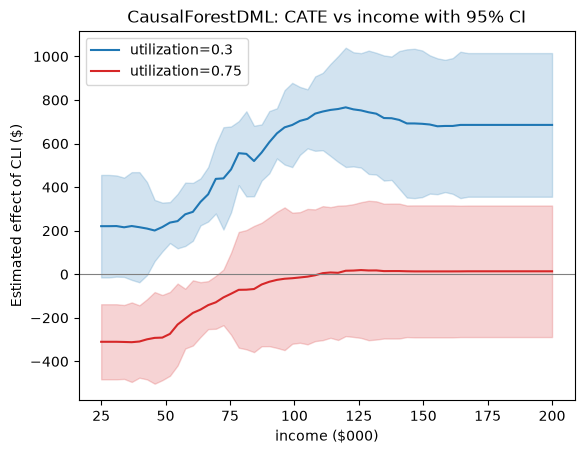

In [8]:
# CATE as a function of income, holding the others at their median — with 95% CI
grid = np.tile(np.median(X_test, axis=0), (60, 1))
grid[:, 0] = np.linspace(25, 200, 60)                         # income_k
for util, color in [(0.3, "C0"), (0.75, "C3")]:
    g = grid.copy(); g[:, 2] = util
    pt = cf.effect(g); lb, ub = cf.effect_interval(g, alpha=0.05)
    plt.plot(g[:, 0], pt, color=color, label=f"utilization={util}")
    plt.fill_between(g[:, 0], lb, ub, color=color, alpha=.2)
plt.axhline(0, color="grey", lw=.8)
plt.xlabel("income ($000)"); plt.ylabel("Estimated effect of CLI ($)")
plt.title("CausalForestDML: CATE vs income with 95% CI"); plt.legend(); plt.show()

## 2.6 Interpretation: which features drive heterogeneity?

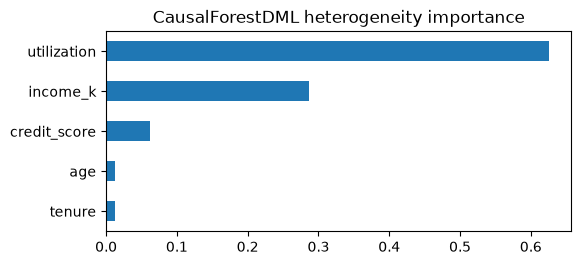

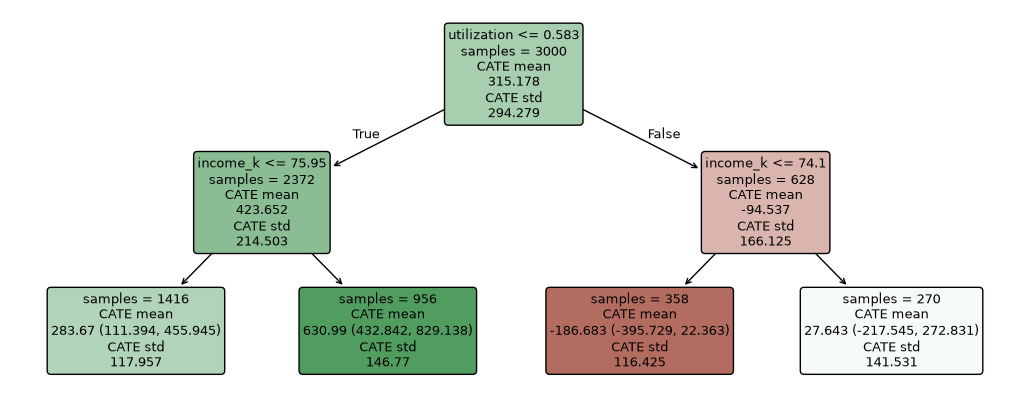

In [9]:
from econml.cate_interpreter import SingleTreeCateInterpreter
pd.Series(cf.feature_importances_, index=X_COLS).sort_values().plot.barh(
    figsize=(6, 2.6), title="CausalForestDML heterogeneity importance"); plt.show()

interp = SingleTreeCateInterpreter(include_model_uncertainty=True, max_depth=2, min_samples_leaf=50)
interp.interpret(cf, X_test)
plt.figure(figsize=(13, 5)); interp.plot(feature_names=X_COLS, fontsize=9); plt.show()

A depth-2 tree summarizing the forest recovers the true structure: a utilization split near 0.6 (true cliff at 0.6) and an income split in the \$70–80K range (true effect rises fastest around \$70K) — a segmentation you can **explain to a credit committee**. Note the leaves with negative CATE: high-utilization customers *reduce* spend after a CLI in this simulation (e.g. debt-stress behavior).

## 2.7 From CATE to decisions: a cost-aware policy
Granting a CLI costs the bank an estimated **\$250 per customer** (expected loss + capital, illustrative). Treat only if $\hat\tau(x) > \$250$.

We compare policies by their **true net value** = $\sum_{\text{treated}} (\tau_i - \text{cost})$ — only computable in simulation, but it shows what's at stake.

In [10]:
COST = 250
def net_value(treat_mask):
    return float(((tau_test - COST) * treat_mask).sum())

policies = {
    "Treat nobody": np.zeros(len(test), bool),
    "Treat everybody": np.ones(len(test), bool),
    "Current bank policy (observed)": test["cli"].values.astype(bool),
    "CATE > cost (LinearDML)": cate["LinearDML"] > COST,
    "CATE > cost (CausalForestDML)": cate["CausalForestDML"] > COST,
    "Oracle (true CATE > cost)": tau_test > COST,
}
pol = pd.DataFrame({
    "% treated": {k: m.mean() * 100 for k, m in policies.items()},
    "true net value ($K)": {k: net_value(m) / 1e3 for k, m in policies.items()},
})
pol

,% treated,true net value ($K)
Treat nobody,0.00,0.00
Treat everybody,100.00,347.23
Current bank policy (observed),60.10,416.81
CATE > cost (LinearDML),58.80,622.54
CATE > cost (CausalForestDML),59.60,661.25
Oracle (true CATE > cost),63.97,687.35


### An *interpretable* policy: SingleTreePolicyInterpreter
Regulators and business owners prefer rules over black-box scores. EconML can learn a shallow decision tree that directly maximizes estimated net value:

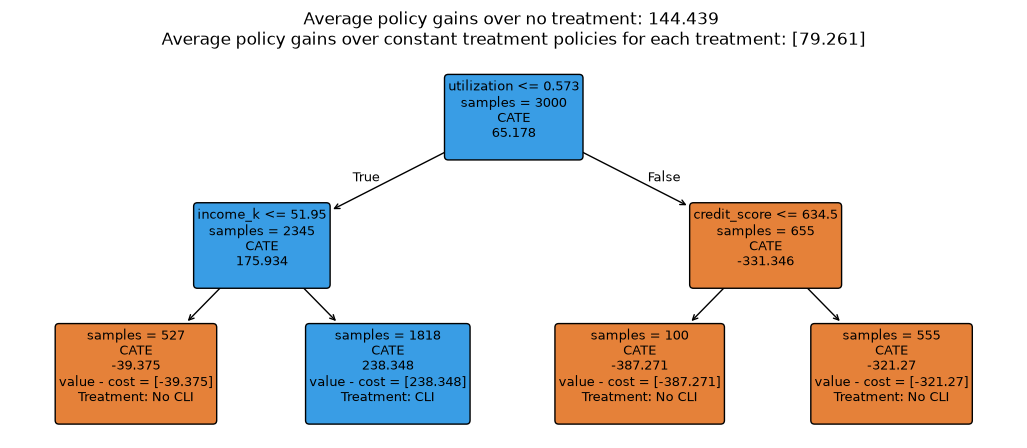

Tree policy: treat 61% of customers, true net value $621K


In [11]:
from econml.cate_interpreter import SingleTreePolicyInterpreter
pol_tree = SingleTreePolicyInterpreter(risk_level=None, max_depth=2, min_samples_leaf=100)
pol_tree.interpret(cf, X_test, sample_treatment_costs=COST)
plt.figure(figsize=(13, 5)); pol_tree.plot(feature_names=X_COLS, treatment_names=["No CLI", "CLI"], fontsize=9); plt.show()

tree_mask = pol_tree.treat(X_test).astype(bool)
print(f"Tree policy: treat {tree_mask.mean():.0%} of customers, true net value ${net_value(tree_mask)/1e3:,.0f}K")

---
## ✋ Exercise 2.1 (6 min) — price sensitivity of the policy
Finance revises the cost of a CLI to **\$500**.
1. Recompute the CausalForestDML policy (`cate["CausalForestDML"] > 500`) and its true net value at the new cost.
2. What share of customers is treated now vs at \$250?
3. **Bonus:** use `cf.effect_interval(X_test, alpha=0.1)` and treat only where the **lower** bound exceeds the cost (a *conservative* policy). How does value change? When would a risk officer prefer this?

In [12]:
# YOUR CODE HERE
NEW_COST = 500

**✅ Solution (instructor copy)**

In [13]:
NEW_COST = 500
tau_cf = cate["CausalForestDML"]
m_point = tau_cf > NEW_COST
lb, ub = cf.effect_interval(X_test, alpha=0.1)
m_cons = lb > NEW_COST
val = lambda m: float(((tau_test - NEW_COST) * m).sum()) / 1e3
print(f"Point-estimate policy : treat {m_point.mean():.1%}, net ${val(m_point):,.0f}K")
print(f"Conservative (LB>cost): treat {m_cons.mean():.1%}, net ${val(m_cons):,.0f}K")
print(f"Oracle                : treat {(tau_test>NEW_COST).mean():.1%}, net ${val(tau_test>NEW_COST):,.0f}K")
# The conservative policy treats far fewer customers: lower total value but a much higher
# hit-rate -- preferred when wrong treatments are costly or must be justified individually.

Point-estimate policy : treat 28.9%, net $265K
Conservative (LB>cost): treat 15.5%, net $184K
Oracle                : treat 40.0%, net $299K


## ✋ Exercise 2.2 (5 min) — EconML inside DoWhy
DoWhy can call any EconML estimator as its *estimation* step, so you get DoWhy's graph-based identification **and** refuters around a CATE model.
Use `model.estimate_effect(..., method_name="backdoor.econml.dml.CausalForestDML", method_params={...})` with the Module-1 graph, then run a `placebo_treatment_refuter` (`num_simulations=3` to keep it fast).

*Hint:* `method_params={"init_params": {...}, "fit_params": {}}` and pass `effect_modifiers=X_COLS` to `CausalModel`.

In [14]:
# YOUR CODE HERE
from dowhy import CausalModel
from causal_utils import CREDIT_LINE_EDGES, edges_to_dot

**✅ Solution (instructor copy)**

In [15]:
import logging; logging.getLogger("dowhy").setLevel(logging.ERROR)
from dowhy import CausalModel
from causal_utils import CREDIT_LINE_EDGES, edges_to_dot
cols = X_COLS + ["promo_email", "cli", "new_balance", "spend"]
dw = CausalModel(data=train[cols], treatment="cli", outcome="spend",
                 graph=edges_to_dot(CREDIT_LINE_EDGES), effect_modifiers=X_COLS)
ident = dw.identify_effect(proceed_when_unidentifiable=True)
dw_est = dw.estimate_effect(
    ident, method_name="backdoor.econml.dml.CausalForestDML", effect_modifiers=X_COLS,
    method_params={"init_params": dict(model_y=reg(), model_t=clf(), discrete_treatment=True,
                                       cv=3, n_estimators=200, min_samples_leaf=20, random_state=0),
                   "fit_params": {}})
print(f"DoWhy + CausalForestDML ATE: ${dw_est.value:,.0f}")
print(dw.refute_estimate(ident, dw_est, method_name="placebo_treatment_refuter",
                         placebo_type="permute", num_simulations=3, random_seed=0))

DoWhy + CausalForestDML ATE: $317


Refute: Use a Placebo Treatment
Estimated effect:317.4510658707523
New effect:7.095670614972797
p value:0.3449291839696037



## 🔑 Key takeaways — Module 2
1. **DML = residualize Y, residualize T, regress residuals** — with cross-fitting. Any ML model can be used for the nuisances.
2. Choose the **final-stage** form to match the heterogeneity you expect: linear for interpretability, forests for flexibility.
3. Select CATE models with **R-score** on held-out data; always report **confidence intervals**.
4. The decision-relevant quantity is usually **CATE vs cost**, not the ATE. Policy trees make the rule explainable.
5. For **unmeasured confounding** with a valid instrument, look at `OrthoIV` / `DRIV` (same API).

➡️ Next: `03_Uplift_Modeling_CausalML.ipynb`